# Level 3 – Task 3: NLP – Sentiment Analysis
**Dataset:** Social Media Sentiment Dataset  
**Tools:** Python, nltk, TextBlob, pandas, matplotlib, wordcloud

## 1. Load the Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob
from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import re
import os

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('punkt', quiet=True)

os.makedirs('plots', exist_ok=True)

df = pd.read_csv('../Data Set For Task/3) Sentiment dataset.csv')
df = df[['Text', 'Sentiment']].dropna()
df['Text']      = df['Text'].astype(str).str.strip()
df['Sentiment'] = df['Sentiment'].astype(str).str.strip()

print('Shape:', df.shape)
df.head()

Shape: (732, 2)


,Text,Sentiment
0,Enjoying a beautiful day at the park!,Positive
1,Traffic was terrible this morning.,Negative
2,Just finished an amazing workout! 💪,Positive
3,Excited about the upcoming weekend getaway!,Positive
4,Trying out a new recipe for dinner tonight.,Neutral


## 2. Text Preprocessing
Tokenization, stopword removal, and lemmatization.

In [2]:
stop_words  = set(stopwords.words('english'))
lemmatizer  = WordNetLemmatizer()

def preprocess(text):
    text = re.sub(r'http\S+|@\w+|#\w+|[^a-zA-Z\s]', '', text).lower()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

df['clean_text'] = df['Text'].apply(preprocess)
df[['Text', 'clean_text']].head()

,Text,clean_text
0,Enjoying a beautiful day at the park!,enjoying beautiful day park
1,Traffic was terrible this morning.,traffic terrible morning
2,Just finished an amazing workout! 💪,finished amazing workout
3,Excited about the upcoming weekend getaway!,excited upcoming weekend getaway
4,Trying out a new recipe for dinner tonight.,trying new recipe dinner tonight


## 3. Sentiment Analysis with TextBlob
Map polarity score → Positive / Negative / Neutral.

In [3]:
def get_sentiment(text):
    polarity = TextBlob(text).sentiment.polarity
    if polarity > 0.1:
        return 'Positive'
    elif polarity < -0.1:
        return 'Negative'
    else:
        return 'Neutral'

df['predicted_sentiment'] = df['clean_text'].apply(get_sentiment)

print('Predicted Sentiment Distribution:')
print(df['predicted_sentiment'].value_counts())

Predicted Sentiment Distribution:
predicted_sentiment
Neutral     401
Positive    245
Negative     86
Name: count, dtype: int64


## 4. Sentiment Distribution – Bar Chart

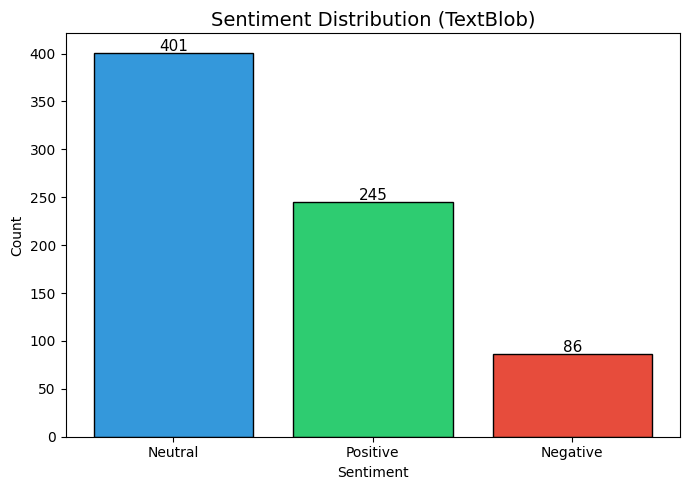

In [4]:
colors = {'Positive': '#2ecc71', 'Neutral': '#3498db', 'Negative': '#e74c3c'}
counts = df['predicted_sentiment'].value_counts()

plt.figure(figsize=(7, 5))
bars = plt.bar(counts.index, counts.values,
               color=[colors[s] for s in counts.index], edgecolor='black')
plt.title('Sentiment Distribution (TextBlob)', fontsize=14)
plt.xlabel('Sentiment')
plt.ylabel('Count')
for bar, val in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
             str(val), ha='center', fontsize=11)
plt.tight_layout()
plt.savefig('plots/sentiment_distribution.png', dpi=150)
plt.show()

## 5. Word Cloud – All Text

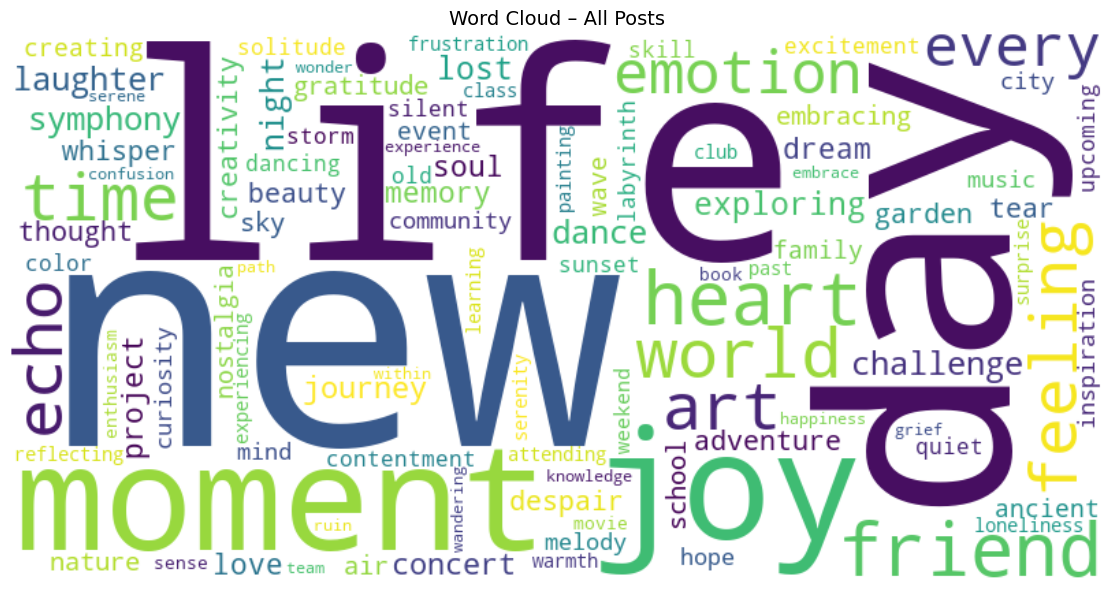

In [5]:
all_text = ' '.join(df['clean_text'])

wc = WordCloud(width=800, height=400, background_color='white',
               colormap='viridis', max_words=100).generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud – All Posts', fontsize=14)
plt.tight_layout()
plt.savefig('plots/wordcloud_all.png', dpi=150)
plt.show()

## 6. Word Clouds by Sentiment

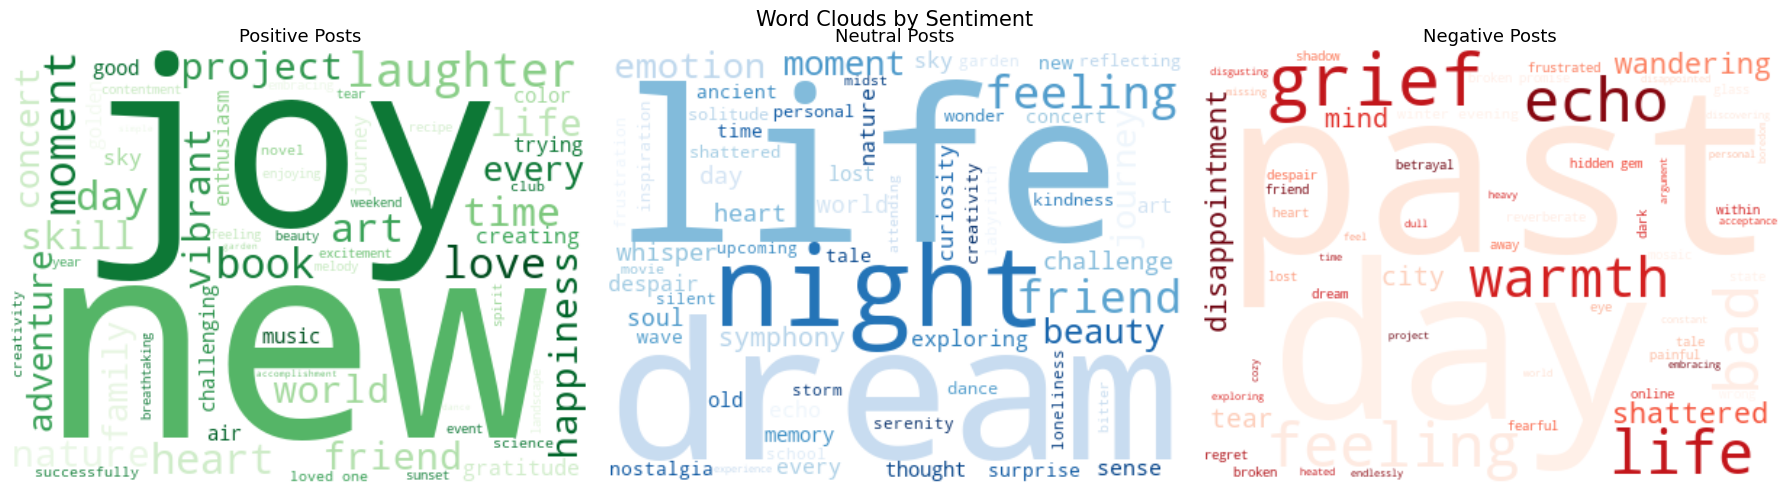

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cmaps = {'Positive': 'Greens', 'Neutral': 'Blues', 'Negative': 'Reds'}

for ax, sentiment in zip(axes, ['Positive', 'Neutral', 'Negative']):
    text = ' '.join(df[df['predicted_sentiment'] == sentiment]['clean_text'])
    if text.strip():
        wc = WordCloud(width=400, height=300, background_color='white',
                       colormap=cmaps[sentiment], max_words=60).generate(text)
        ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'{sentiment} Posts', fontsize=13)

plt.suptitle('Word Clouds by Sentiment', fontsize=15)
plt.tight_layout()
plt.savefig('plots/wordclouds_by_sentiment.png', dpi=150)
plt.show()

## 7. Polarity Score Distribution

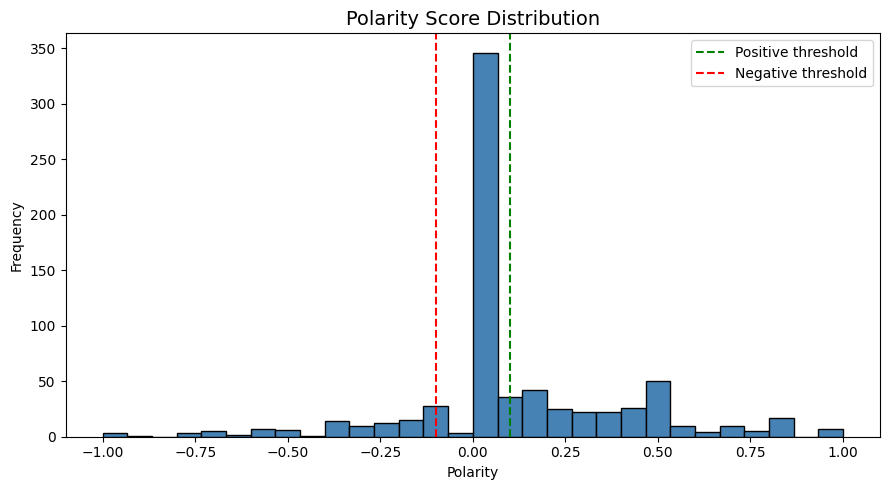

In [7]:
df['polarity'] = df['clean_text'].apply(lambda x: TextBlob(x).sentiment.polarity)

plt.figure(figsize=(9, 5))
plt.hist(df['polarity'], bins=30, color='steelblue', edgecolor='black')
plt.axvline(0.1,  color='green', linestyle='--', label='Positive threshold')
plt.axvline(-0.1, color='red',   linestyle='--', label='Negative threshold')
plt.title('Polarity Score Distribution', fontsize=14)
plt.xlabel('Polarity')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.savefig('plots/polarity_distribution.png', dpi=150)
plt.show()

## 8. Top Original Sentiment Labels

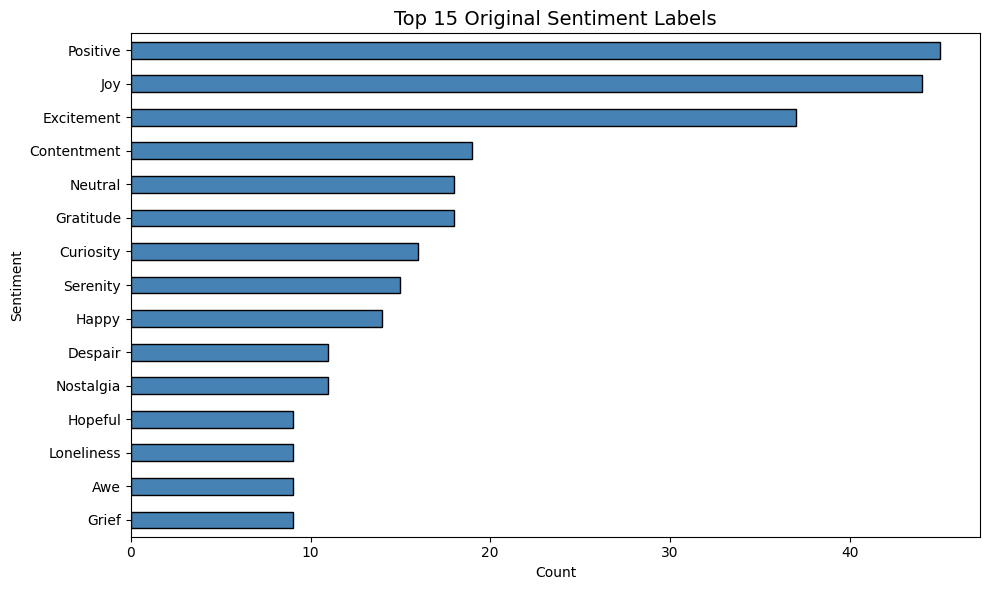

In [8]:
top_labels = df['Sentiment'].value_counts().head(15)

plt.figure(figsize=(10, 6))
top_labels.plot(kind='barh', color='steelblue', edgecolor='black')
plt.title('Top 15 Original Sentiment Labels', fontsize=14)
plt.xlabel('Count')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('plots/top_sentiment_labels.png', dpi=150)
plt.show()

## Summary

| Step | Description |
|------|-------------|
| Preprocessing | Removed URLs, mentions, hashtags, punctuation; lemmatized tokens; removed stopwords |
| Sentiment Analysis | Used TextBlob polarity score to classify as Positive / Neutral / Negative |
| Word Cloud | Visualized most frequent words overall and per sentiment |
| Polarity Distribution | Histogram showing spread of polarity scores across all posts |